# Plot the LER data

In [70]:
distances = [3, 5, 7, 9, 11]

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import glob
import json

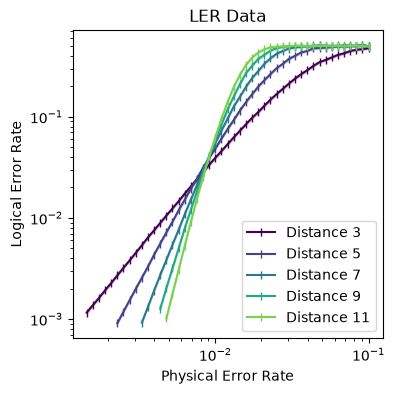

In [ ]:
f, ax = plt.subplots(1, 1, figsize=(4, 4))
cmap = plt.get_cmap("viridis")
colors = [cmap(i / len(distances)) for i in range(len(distances))]
for distance in distances:
    # Loop over filenames with this distance, and plot the corresponding LER data
    # Find the filenames corresponding to this distance
    # Look in current directory for files starting with distance3, etc.
    filenames = glob.glob(f"./distance{distance}_*")
    probs = []
    ler = []
    ci95 = []
    nsamples = []
    for filename in filenames:
        try:
            # Extract the probability from the filename
            probability = float(filename.split("_")[1][4:])
            probs.append(probability)
            # Load the json file
            with open(filename, "r") as f:
                data = json.load(f)
            ler.append(data["failure_rate"])
            ci95.append(data["failure_rate_ci95"])
            nsamples.append(data["number_of_samples"])
        except:
            pass

    sort_idx = np.argsort(probs)
    probs = np.array(probs)[sort_idx]
    ler = np.array(ler)[sort_idx]
    ci95 = np.array(ci95)[sort_idx]
    nsamples = np.array(nsamples)[sort_idx]
    ci95 = np.array(ci95)
    ler = np.array(ler)
    nsamples = np.array(nsamples)
    ax.plot(probs, ler, '-|', label=f"Distance {distance}", color=colors[distances.index(distance)])
    ax.fill_between(probs, np.array(ci95[:, 0]), np.array(ci95[:, 1]), alpha=0.2, color=colors[distances.index(distance)])
ax.set_xlabel("Physical Error Rate")
ax.set_ylabel("Logical Error Rate")
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
plt.show()

# Look at number of samples required

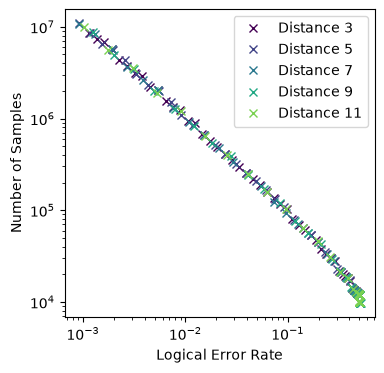

In [28]:
# Plot the number of samples versus the LER
f, ax = plt.subplots(1, 1, figsize=(4, 4))
cmap = plt.get_cmap("viridis")
colors = [cmap(i / len(distances)) for i in range(len(distances))]
for distance in distances:
    # Loop over filenames with this distance, and plot the corresponding LER data
    # Find the filenames corresponding to this distance
    # Look in current directory for files starting with distance3, etc.
    filenames = glob.glob(f"./distance{distance}_*")
    probs = []
    ler = []
    ci95 = []
    nsamples = []
    for filename in filenames:
        try:
            # Extract the probability from the filename
            probability = float(filename.split("_")[1][4:])
            probs.append(probability)
            # Load the json file
            with open(filename, "r") as f:
                data = json.load(f)
            ler.append(data["failure_rate"])
            ci95.append(data["failure_rate_ci95"])
            nsamples.append(data["number_of_samples"])
        except:
            pass

    sort_idx = np.argsort(probs)
    probs = np.array(probs)[sort_idx]
    ler = np.array(ler)[sort_idx]
    ci95 = np.array(ci95)[sort_idx]
    nsamples = np.array(nsamples)[sort_idx]
    ci95 = np.array(ci95)
    ler = np.array(ler)
    nsamples = np.array(nsamples)
    ax.plot(ler, nsamples, 'x', label=f"Distance {distance}", color=colors[distances.index(distance)])
    #ax.fill_between(probs, np.array(ci95[:, 0]), np.array(ci95[:, 1]), alpha=0.2, color=colors[distances.index(distance)])
ax.set_xlabel("Logical Error Rate")
ax.set_ylabel("Number of Samples")
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
plt.show()

# Create a convergence plot with the number of samples

In [32]:
def get_bootstrap_error(data, num_samples=5000):
    results = data['results']
    bootstrap_errors = []
    for _ in range(num_samples):
        sample = np.random.choice(results, size=len(results), replace=True)
        bootstrap_errors.append(np.mean(sample))
    return np.mean(bootstrap_errors), np.std(bootstrap_errors)

[10, 12, 15, 20, 25, 32, 40, 51, 64, 82, 103, 130, 165, 209, 264, 333, 421, 532, 673, 850, 1074, 1357, 1715, 2167, 2738, 3460, 4371, 5523, 6979, 8817]
Sample size: 10, Bootstrap error: 0.09602774390768536
Sample size: 12, Bootstrap error: 0.08048250154881839
Sample size: 15, Bootstrap error: 0.06424864892656414
Sample size: 20, Bootstrap error: 0.0676454514361461
Sample size: 25, Bootstrap error: 0.0539833455799101
Sample size: 32, Bootstrap error: 0.05182484925207212
Sample size: 40, Bootstrap error: 0.042007967994179385
Sample size: 51, Bootstrap error: 0.03286739426143077
Sample size: 64, Bootstrap error: 0.02586846818975517
Sample size: 82, Bootstrap error: 0.020819027013342206
Sample size: 103, Bootstrap error: 0.016638567899539092
Sample size: 130, Bootstrap error: 0.013064516739364533
Sample size: 165, Bootstrap error: 0.011898855961243062
Sample size: 209, Bootstrap error: 0.009455991937466927
Sample size: 264, Bootstrap error: 0.008331228074293448
Sample size: 333, Bootstrap e

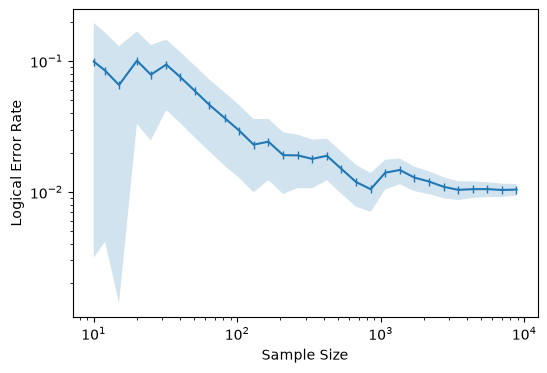

In [ ]:
filename = "./distance3_prob0.00478630092322638_surface_code_results.json"
with open(filename, "r") as f:
    data = json.load(f)

results = data['results']
# Jump by 1000
errors_mean = []
errors_std = []
sample_sizes = np.logspace(1, np.log10(len(results)), 50)[:30]
sample_sizes = [int(x) for x in sample_sizes]
for sample_size in sample_sizes:
    subset = results[:sample_size]
    mean_error, std_error = get_bootstrap_error({'results': subset})
    print(f"Sample size: {sample_size}, Bootstrap error: {std_error}")
    errors_mean.append(mean_error)
    errors_std.append(std_error)

f, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(sample_sizes, errors_mean, '-|')
ax.fill_between(sample_sizes, np.array(errors_mean) - np.array(errors_std), np.array(errors_mean) + np.array(errors_std), alpha=0.2)
plt.xlabel("Sample Size")
plt.ylabel("Logical Error Rate")
plt.xscale('log')
plt.yscale('log')
plt.show()



# Brayvi-Vargo Results Analysis

[0.00131826 0.00144544 0.00158489 0.0017378  0.00190546 0.0020893
 0.00229087 0.00251189 0.00275423 0.00301995 0.00331131 0.00363078
 0.00398107 0.00436516 0.0047863  0.00524807 0.0057544  0.00630957
 0.00691831 0.00758578 0.00831764 0.00912011 0.01       0.01096478
 0.01202264 0.01318257 0.0144544  0.01584893 0.01737801 0.01905461
 0.02089296 0.02290868 0.02511886 0.02754229 0.03019952 0.03311311
 0.03630781 0.03981072 0.04365158 0.04786301 0.05248075 0.05754399
 0.06309573 0.0691831  0.07585776 0.08317638 0.09120108 0.1       ] [0.00098139 0.00115864 0.00136971 0.00161754 0.00192182 0.00227487
 0.00270288 0.00321157 0.00379502 0.00450911 0.0053685  0.00642264
 0.00754473 0.00892648 0.01055235 0.01241549 0.0146276  0.01737396
 0.02049411 0.02422486 0.0284751  0.03358635 0.03935582 0.04582636
 0.0536711  0.06265586 0.07274632 0.08449943 0.09783587 0.11127459
 0.12878484 0.14774443 0.16785095 0.18883364 0.2129642  0.23859231
 0.26414845 0.28914269 0.31874687 0.3472739  0.36507771 0.3865

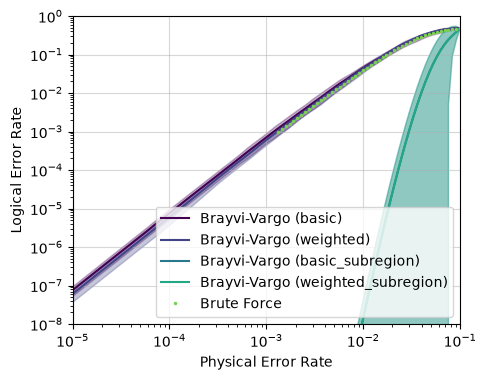

In [92]:
flipper_types = ['basic', 'weighted', 'basic_subregion', 'weighted_subregion']
npts = 101
distance = 3
burnin = 10000

color = {'basic': cmap(0.0),
         'weighted': cmap(0.2),
         'basic_subregion': cmap(0.4),
         'weighted_subregion': cmap(0.6)}

f, ax = plt.subplots(1, 1, figsize=(5, 4))

for flipper_type in flipper_types:
    physical_error_rates = []
    ler = []
    for seed in range(10):
        filename = f"bv_distance{distance}__burnin{burnin}__error_target0.01__flipper_type{flipper_type}__npts{npts}_seed{seed}_surface_code_bv_results.json"
        with open(filename, "r") as f:
            data = json.load(f)
        physical_error_rates.append(data['physical_error_rates'])
        ler.append(data['probabilities'])
    ax.plot(physical_error_rates[0], np.average(ler, axis=0), '-', color=color[flipper_type], label=f'Brayvi-Vargo ({flipper_type})')
    ax.fill_between(physical_error_rates[0], np.average(ler, axis=0) - np.std(ler, axis=0), np.average(ler, axis=0) + np.std(ler, axis=0), color=color[flipper_type], alpha=0.3)


# Add the brute force data
for distance in [3]:
    # Loop over filenames with this distance, and plot the corresponding LER data
    # Find the filenames corresponding to this distance
    # Look in current directory for files starting with distance3, etc.
    filenames = glob.glob(f"./distance{distance}_*")
    probs = []
    ler = []
    ci95 = []
    nsamples = []
    for filename in filenames:
        # Extract the probability from the filename
        probability = filename.split("_")[1][4:]
        if probability == "ace":
            continue
        probability = float(filename.split("_")[1][4:])
        # Load the json file
        with open(filename, "r") as f:
            data = json.load(f)
        probs.append(probability)
        ler.append(data["failure_rate"])
        ci95.append(data["failure_rate_ci95"])
        nsamples.append(data["number_of_samples"])

    sort_idx = np.argsort(probs)
    probs = np.array(probs)[sort_idx]
    ler = np.array(ler)[sort_idx]
    ci95 = np.array(ci95)[sort_idx]
    nsamples = np.array(nsamples)[sort_idx]
    ci95 = np.array(ci95)
    ler = np.array(ler)
    nsamples = np.array(nsamples)
    print(probs, ler)
    ax.plot(probs, ler, '.', label=f"Brute Force", color=cmap(0.8), markersize=3)

plt.xlabel("Physical Error Rate")
plt.ylabel("Logical Error Rate")
plt.xscale('log')
plt.yscale('log')
ax.set_xlim(1e-5, 1e-1)
ax.set_ylim(1e-8, 1e0)
ax.grid(True, alpha=0.5)
plt.legend()

# Plot the number of decoder calls

[0.00131826 0.00144544 0.00158489 0.0017378  0.00190546 0.0020893
 0.00229087 0.00251189 0.00275423 0.00301995 0.00331131 0.00363078
 0.00398107 0.00436516 0.0047863  0.00524807 0.0057544  0.00630957
 0.00691831 0.00758578 0.00831764 0.00912011 0.01       0.01096478
 0.01202264 0.01318257 0.0144544  0.01584893 0.01737801 0.01905461
 0.02089296 0.02290868 0.02511886 0.02754229 0.03019952 0.03311311
 0.03630781 0.03981072 0.04365158 0.04786301 0.05248075 0.05754399
 0.06309573 0.0691831  0.07585776 0.08317638 0.09120108 0.1       ] [0.00098139 0.00115864 0.00136971 0.00161754 0.00192182 0.00227487
 0.00270288 0.00321157 0.00379502 0.00450911 0.0053685  0.00642264
 0.00754473 0.00892648 0.01055235 0.01241549 0.0146276  0.01737396
 0.02049411 0.02422486 0.0284751  0.03358635 0.03935582 0.04582636
 0.0536711  0.06265586 0.07274632 0.08449943 0.09783587 0.11127459
 0.12878484 0.14774443 0.16785095 0.18883364 0.2129642  0.23859231
 0.26414845 0.28914269 0.31874687 0.3472739  0.36507771 0.3865

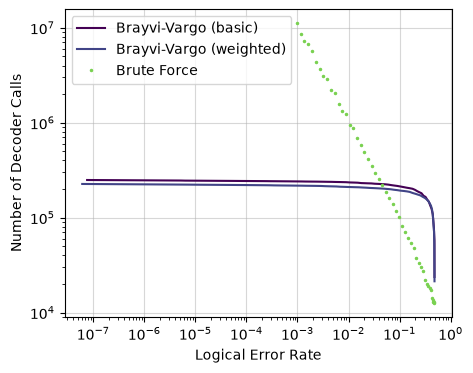

In [104]:
flipper_types = ['basic', 'weighted']#, 'basic_subregion', 'weighted_subregion']
npts = 101
distance = 3
burnin = 10000

color = {'basic': cmap(0.0),
         'weighted': cmap(0.2),
         'basic_subregion': cmap(0.4),
         'weighted_subregion': cmap(0.6)}

f, ax = plt.subplots(1, 1, figsize=(5, 4))

for flipper_type in flipper_types:
    physical_error_rates = []
    ler = []
    decoder_calls = []
    for seed in range(10):
        filename = f"bv_distance{distance}__burnin{burnin}__error_target0.01__flipper_type{flipper_type}__npts{npts}_seed{seed}_surface_code_bv_results.json"
        with open(filename, "r") as f:
            data = json.load(f)
        physical_error_rates.append(data['physical_error_rates'])
        ler.append(data['probabilities'])
        decoder_calls.append(np.cumsum([mr['number_of_decoder_calls'] for mr in data['metropolis_results']]))
    ax.plot(np.average(ler, axis=0), np.average(decoder_calls, axis=0), '-', color=color[flipper_type], label=f'Brayvi-Vargo ({flipper_type})')

# Add the brute force data
for distance in [3]:
    # Loop over filenames with this distance, and plot the corresponding LER data
    # Find the filenames corresponding to this distance
    # Look in current directory for files starting with distance3, etc.
    filenames = glob.glob(f"./distance{distance}_*")
    probs = []
    ler = []
    ci95 = []
    nsamples = []
    for filename in filenames:
        # Extract the probability from the filename
        probability = filename.split("_")[1][4:]
        if probability == "ace":
            continue
        probability = float(filename.split("_")[1][4:])
        # Load the json file
        with open(filename, "r") as f:
            data = json.load(f)
        probs.append(probability)
        ler.append(data["failure_rate"])
        ci95.append(data["failure_rate_ci95"])
        nsamples.append(data["number_of_samples"])

    sort_idx = np.argsort(probs)
    probs = np.array(probs)[sort_idx]
    ler = np.array(ler)[sort_idx]
    ci95 = np.array(ci95)[sort_idx]
    nsamples = np.array(nsamples)[sort_idx]
    ci95 = np.array(ci95)
    ler = np.array(ler)
    nsamples = np.array(nsamples)
    print(probs, ler)
    ax.plot(ler, nsamples, '.', label=f"Brute Force", color=cmap(0.8), markersize=3)

plt.ylabel("Number of Decoder Calls")
plt.xlabel("Logical Error Rate")
plt.xscale('log')
plt.yscale('log')
ax.grid(True, alpha=0.5)
plt.legend()